<a href="https://colab.research.google.com/github/Ben-AC-Math/Generalisable_PI/blob/new/PIPN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Set the working directory for the Code. 

In [1]:
%cd /content/drive/MyDrive/PIPN

/content/drive/MyDrive/PIPN


Import relevant packages/libraries

In [2]:
import os
import numpy as np
import itertools
import math, random
random.seed = 42
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils
from torch.autograd import grad, Variable
import torch.optim as optim

Point Sampler for the Kaggle implementation

In [3]:
arr = np.random.randint(5, size=(10,5))

#idx = np.random.randint(10, size=2)
y = arr[np.random.choice(arr.shape[0], 2, replace=False), :]
print(y)
print(arr)



[[1 2 4 2 1]
 [4 4 2 2 3]]
[[1 2 0 1 2]
 [3 3 1 3 3]
 [4 4 2 2 3]
 [1 4 0 1 0]
 [3 4 3 2 4]
 [1 1 3 2 2]
 [4 1 4 3 1]
 [0 4 3 1 2]
 [1 2 4 2 1]
 [3 0 3 0 0]]


In [4]:
class PointSampler(object):
    def __init__(self, output_size):
        assert isinstance(output_size, int)
        self.output_size = output_size

    def __call__(self, points):

        sampled_points = points[np.random.choice(points.shape[0], self.output_size, replace=False), :]
       
        return sampled_points

class Normalize(object):
    def __call__(self, pointcloud):
        assert len(pointcloud.shape)==2
        
        norm_pointcloud = pointcloud - np.mean(pointcloud, axis=0) 
        norm_pointcloud /= np.max(np.linalg.norm(norm_pointcloud, axis=1))

        return  norm_pointcloud

class ToTensor(object):
    def __call__(self, pointcloud):
        assert len(pointcloud.shape)==2

        return torch.from_numpy(pointcloud)

def default_transforms():
  return transforms.Compose([
                            PointSampler(10000),
                            Normalize(),
                            ToTensor()
                          ])

Method for importing our data. Each mesh needs to be in the meshes folder and each mesh should be labelled as v1, v2, vn. Currently the code assumes that there are 3 files in the folder: 'Ux.txt', 'Uy.txt' and 'elements.txt'

In [5]:
class PointCloudData(Dataset):
    def __init__(self, root_dir, valid=False, folder="test", transform=default_transforms()):
        self.root_dir = root_dir
        self.scaler = MinMaxScaler()
        self.pointSampler = PointSampler(output_size=5000)
        folders = os.listdir(root_dir)
        self.transforms = transform if not valid else default_transforms()
        self.files = []

        for version in folders:
          version_path = os.path.join(self.root_dir, version)

          sample = {}
          sample['Ux'] = os.path.join(version_path, 'Ux.txt')
          sample['Uy'] = os.path.join(version_path, 'Uy.txt')
          sample['elements'] = os.path.join(version_path, 'elements.txt')
          self.files.append(sample)

        print(self.files)   
       

    def __len__(self):
        return len(self.files)


    def __getitem__(self, idx):
      ux_path = self.files[idx]['Ux']
      uy_path = self.files[idx]['Uy']
      ele_path = self.files[idx]['elements']
      
      input_feature = np.array(pd.read_csv(ux_path, delimiter = "\t"))[:,1:4]
      elements = np.array(pd.read_csv(ele_path, delimiter = "\t"))[:,0:3].astype(int)
      elements = elements - 1
      ux = np.array(pd.read_csv(ux_path, delimiter = "\t"))[:,4]
      uy = np.array(pd.read_csv(uy_path, delimiter = "\t"))[:,4]
      uz = np.zeros((uy.shape[0],1))

      displacement = np.concatenate((ux[:,np.newaxis], uy[:,np.newaxis], uz), axis=1)

      # Create a boolean index that is True for rows where the value in the 3rd column is 10 
      index = (input_feature[:, 1] == 10)

      #BCs is a 3 column array (x,y,z) vectors of displacement BCs or could just be a one column?
      boundary_conditions = np.zeros((input_feature.shape[0],1))

      # Set the values in to 5 when y = 10
      boundary_conditions[index] = 5

      # Create a boolean index that is True for rows where the value in the 3rd column is 0 or 10
      index = (input_feature[:, 1] == 0) | (input_feature[:, 1] == 10)

      # Create a new column with all values set to 0
      bc_present = np.zeros((input_feature.shape[0], 1))

      # Set the values in the new column to 1 for rows where the index is True
      bc_present[index] = 1

      # Concatenate the old array and the new column to create the new array
      input_feature = np.concatenate((input_feature, bc_present, boundary_conditions), axis=1)

      sampled_input_output = np.concatenate((input_feature, displacement), axis=1)

      sampled_input_output = self.pointSampler(sampled_input_output)

      sampled_input_feature = sampled_input_output[:,:5]

      sampled_displacement = sampled_input_output[:,-3:]

      input_coords = sampled_input_feature[:, :3]

      #input_feature = self.scaler.fit_transform(input_feature)
      
      sampled_input_feature = torch.from_numpy(sampled_input_feature)
      sampled_displacement = torch.from_numpy(sampled_displacement)
      input_coords = torch.from_numpy(input_coords)
      
      return {'pointfeature': sampled_input_feature, 'inputcoords':input_coords, 'pointdisp': sampled_displacement}

Checking size of input data. Each mesh should have shape of [num_points, num_input_features] for input and [num_points, num_output_features] for the output

In [6]:
pointDataset_train = PointCloudData(root_dir='/content/drive/MyDrive/PIPN/meshes/Training')
pointDataset_val = PointCloudData(root_dir='/content/drive/MyDrive/PIPN/meshes/Validation')
pointDataset_test = PointCloudData(root_dir='/content/drive/MyDrive/PIPN/meshes/Testing')
print(len(pointDataset_train))
print(len(pointDataset_val))
print(len(pointDataset_test))


for i in range(len(pointDataset_train)):
  print(pointDataset_train[i]['pointfeature'].shape)
  print(pointDataset_train[i]['pointdisp'].shape)
  print('inputcoords:', pointDataset_train[i]['inputcoords'].shape)



[{'Ux': '/content/drive/MyDrive/PIPN/meshes/Training/v1/Ux.txt', 'Uy': '/content/drive/MyDrive/PIPN/meshes/Training/v1/Uy.txt', 'elements': '/content/drive/MyDrive/PIPN/meshes/Training/v1/elements.txt'}, {'Ux': '/content/drive/MyDrive/PIPN/meshes/Training/v3/Ux.txt', 'Uy': '/content/drive/MyDrive/PIPN/meshes/Training/v3/Uy.txt', 'elements': '/content/drive/MyDrive/PIPN/meshes/Training/v3/elements.txt'}, {'Ux': '/content/drive/MyDrive/PIPN/meshes/Training/v2/Ux.txt', 'Uy': '/content/drive/MyDrive/PIPN/meshes/Training/v2/Uy.txt', 'elements': '/content/drive/MyDrive/PIPN/meshes/Training/v2/elements.txt'}, {'Ux': '/content/drive/MyDrive/PIPN/meshes/Training/v4/Ux.txt', 'Uy': '/content/drive/MyDrive/PIPN/meshes/Training/v4/Uy.txt', 'elements': '/content/drive/MyDrive/PIPN/meshes/Training/v4/elements.txt'}]
[{'Ux': '/content/drive/MyDrive/PIPN/meshes/Validation/v5/Ux.txt', 'Uy': '/content/drive/MyDrive/PIPN/meshes/Validation/v5/Uy.txt', 'elements': '/content/drive/MyDrive/PIPN/meshes/Validat

Loading the dataset for the training. Need to initiate the validation loader. 


In [7]:
train_loader = DataLoader(dataset=pointDataset_train, batch_size=2, shuffle=True)

valid_loader = DataLoader(dataset=pointDataset_val, batch_size=2, shuffle=True)

#batch = next(iter(train_loader))

#batch['pointdisp'].shape

Here we outline the network architecture. The network is based off the following schematic:

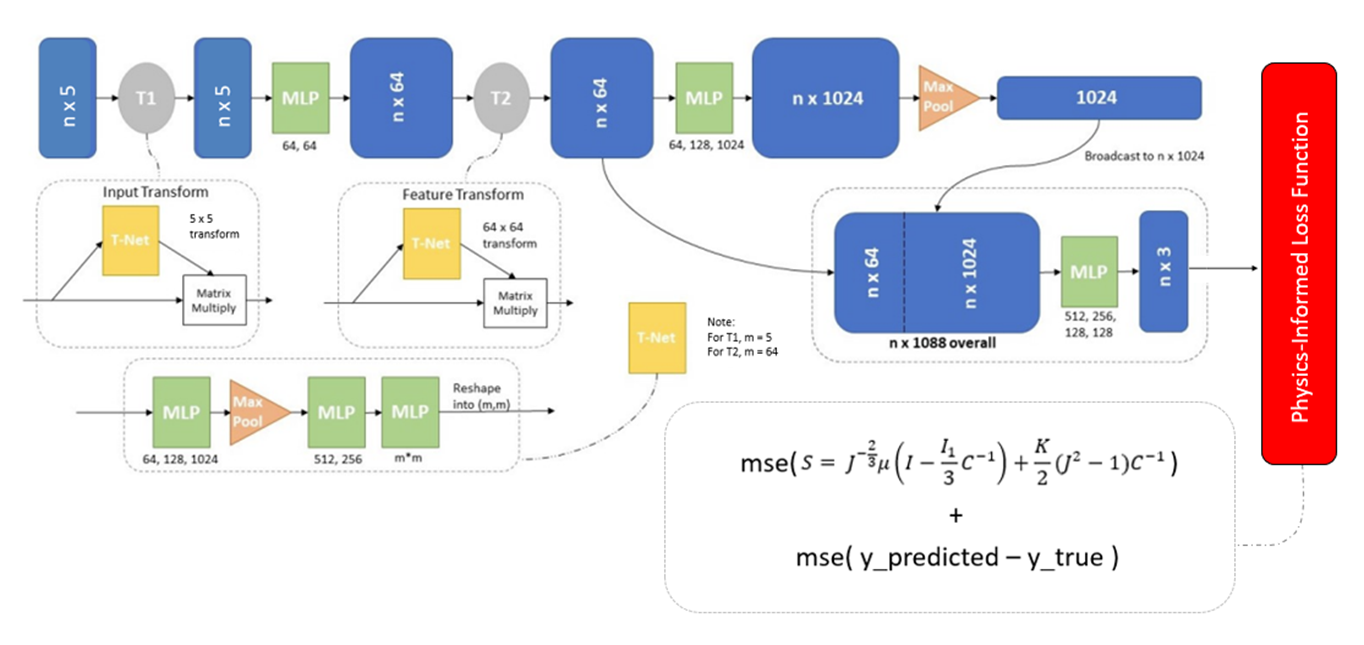


In [8]:
class Tnet(nn.Module):
    def __init__(self, k=5):
        super().__init__()
        self.k=k
        self.conv1 = nn.Conv1d(k,64,1)
        self.conv2 = nn.Conv1d(64,128,1)
        self.conv3 = nn.Conv1d(128,1024,1)
        self.fc1 = nn.Linear(1024,512)
        self.fc2 = nn.Linear(512,256)
        self.fc3 = nn.Linear(256,k*k)

        self.bn1 = nn.BatchNorm1d(64)
        self.bn2 = nn.BatchNorm1d(128)
        self.bn3 = nn.BatchNorm1d(1024)
        self.bn4 = nn.BatchNorm1d(512)
        self.bn5 = nn.BatchNorm1d(256)


    def forward(self, input):
        # input.shape == (bs,n,3)
        bs = input.size(0)
        xb = F.relu(self.bn1(self.conv1(input)))
        xb = F.relu(self.bn2(self.conv2(xb)))
        xb = F.relu(self.bn3(self.conv3(xb)))
        pool = nn.MaxPool1d(xb.size(-1))(xb)
        flat = nn.Flatten(1)(pool)
        xb = F.relu(self.bn4(self.fc1(flat)))
        xb = F.relu(self.bn5(self.fc2(xb)))

        #initialize as identity
        init = torch.eye(self.k, requires_grad=True).repeat(bs,1,1)
        if xb.is_cuda:
            init=init.cuda()
        matrix = self.fc3(xb).view(-1,self.k,self.k) + init
        return matrix

class Transform(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_transform = Tnet(k=5)
        self.feature_transform = Tnet(k=64)
        self.conv1 = nn.Conv1d(5,64,1)

        self.conv2 = nn.Conv1d(64,128,1)
        self.conv3 = nn.Conv1d(128,1024,1)

        self.bn1 = nn.BatchNorm1d(64)
        self.bn2 = nn.BatchNorm1d(128)
        self.bn3 = nn.BatchNorm1d(1024)

    def forward(self, input):
        matrix3x3 = self.input_transform(input)
        # batch matrix multiplication
        xb = torch.bmm(torch.transpose(input,1,2), matrix3x3).transpose(1,2)

        xb = F.relu(self.bn1(self.conv1(xb)))

        matrix64x64 = self.feature_transform(xb)
        out_t2 = torch.bmm(torch.transpose(xb,1,2), matrix64x64).transpose(1,2)

        xb = F.relu(self.bn2(self.conv2(out_t2)))
        xb = self.bn3(self.conv3(xb))
        xb = nn.MaxPool1d(xb.size(-1))(xb)
        output = nn.Flatten(1)(xb)
        output = output.view(-1, 1024, 1).repeat(1, 1, input.shape[2])
        # print('output dim:', output.shape)
        # print('out_t2 dim:', out_t2.shape)
        concat_out = torch.concat([out_t2, output], dim=1)

        # print('concat_out dim:', concat_out.shape)

        return concat_out

class PointNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.transform = Transform()
        self.fc1 = nn.Conv1d(1088, 512, 1)
        self.fc2 = nn.Conv1d(512, 256, 1)
        self.fc3 = nn.Conv1d(256, 128, 1)
        self.fc4 = nn.Conv1d(128, 128, 1)
        self.fc5 = nn.Conv1d(128, 3, 1)

        self.bn1 = nn.BatchNorm1d(512)
        self.bn2 = nn.BatchNorm1d(256)
        self.bn3 = nn.BatchNorm1d(128)
        self.bn4 = nn.BatchNorm1d(128)
    
        #self.dropout = nn.Dropout(p=0.3)

    def forward(self, input):
        # print('input shape (PointNet):', input.shape)
        xb = self.transform(input)
        xb = F.relu(self.bn1(self.fc1(xb)))
        xb = F.relu(self.bn2(self.fc2(xb)))
        xb = F.relu(self.bn3(self.fc3(xb)))
        xb = F.relu(self.bn4(self.fc4(xb)))

        output = self.fc5(xb)

        return output

Here I call the pointnet and pass the inputs through the network to check on the desired shape

In [9]:
pointnet = PointNet()

for i, data in enumerate(train_loader, 0):
  #print(data.size(0))
  inputs, labels = data['pointfeature'].float(), data['pointdisp'].float()
  inputs  = inputs.transpose(1,2)
  labels = labels.transpose(1,2)

  outputs = pointnet(inputs)

Here the hyperparameters can be assainged 

In [10]:
lr = 0.0002
patience = 30
start_epoch = 0
epochs = 100
print_freq = 20
save_folder = '/content/drive/MyDrive/PIPN/saved_models'

The custom training function is outlined below. It has training and validation loop inside. 

In [11]:
# how to calculate the loss for each epoch => https://discuss.pytorch.org/t/plotting-loss-curve/42632
def train(train_loader, model, optimizer, criterion):
    # Ensure dropout layers are in train mode
    model.train()
    
    running_loss = 0.0
    running_mse_loss = 0.0
    running_pinn_loss = 0.0

    # Batches
    # here train_loader returns only x since we use CustomDataset calss and __getitem__ returns only x
    for i_batch, data in enumerate(train_loader):

        input, labels, coords = data['pointfeature'].float(), data['pointdisp'].float(), data['inputcoords'].float()
        input  = input.transpose(1,2)
        y = labels.transpose(1,2)
        coords = coords.transpose(1,2)

        # Zero gradients
        optimizer.zero_grad()

        input_variable = input.clone().detach().requires_grad_(True)
        coords_variable = coords.clone().detach().requires_grad_(True)# print the created tensors
        y_hat = model(input)

        #print(inputs.grad)
      
        #input_coords = data.pos.to(device)

        multitask_loss, mse_loss, pinn_loss = criterion(y_hat, y, input_variable, model)
        # print('average total loss:', multitask_loss.item())
        # print('average mse loss:', mse_loss.item())
        # print('average pinn loss:', pinn_loss.item())

        
        multitask_loss.backward()
        #multitask_loss.backward(torch.ones_like(multitask_loss))

        #print('PINN loss shpae: ',pinn_loss.shape)

        optimizer.step()
        # this can be used if your all batches have equal number of data points including the last batch
        # running_loss += loss.item()
        # if the last batch is smaller than the others
        # data.num_graphs gives the number of graphs per data or batch
        running_loss += multitask_loss.item() * data['pointfeature'].shape[0]
        #running_loss += torch.tensor(multitask_loss) * data['pointfeature'].shape[0]
        #running_chamfer_loss += chamfer_loss.item() * data.num_graphs
        running_mse_loss += mse_loss.item() * data['pointfeature'].shape[0]
        running_pinn_loss += pinn_loss.item() * data['pointfeature'].shape[0]
        #running_pinn_loss += torch.tensor(pinn_loss) * data['pointfeature'].shape[0]
        # print('average total loss:', running_loss)
        # print('average mse loss:', running_mse_loss)
        # print('average pinn loss:', running_pinn_loss)


    # average training loss => total loss for each epoch (compute by taking sum of each batch loss) devide by total number of batches (i.e. len(train_loader))
    # loss = running_loss / len(train_loader)
    # If you just would like to plot the loss for each epoch, divide the running_loss by the number of batches and append it to loss_values in each epoch.
    # Note, that this might give you a slightly biased loss if the last batch is smaller than the others, so let me know if you need the exact loss.
    # len(train_loader.dataset) gives total number of graphs in the training dataset
    loss = running_loss / len(train_loader.dataset)
    #loss_chamfer = running_chamfer_loss / len(train_loader.dataset)
    loss_mse = running_mse_loss / len(train_loader.dataset)
    loss_pinn = running_pinn_loss / len(train_loader.dataset)

    # print('average total loss:', loss)
    # print('average mse loss:', loss_mse)
    # print('average pinn loss:', loss_pinn)
    
    return loss, loss_mse, loss_pinn
    #return loss, loss_mse
	
	
	
def valid(val_loader, model, criterion):
    model.eval()  # eval mode (no dropout or batchnorm)
    
    running_val_loss = 0.0
    running_mse_loss = 0.0
    running_pinn_loss = 0.0

    with torch.no_grad():
        # Batches
        # here val_loader returns only x since we use CustomDataset class and __getitem__ returns only x
        for i_batch, data in enumerate(val_loader):
            # Set device options
            inputs, labels, coords = data['pointfeature'].float(), data['pointdisp'].float(), data['inputcoords'].float()
            inputs  = inputs.transpose(1,2)
            y = labels.transpose(1,2)

            # model(x) returns both encoded and decoded vectors hence we need to define two variables to hold these two values.
            # _ to hold encoded vector and y_hat to hold reconstructed image
            y_hat = model(input)

            multitask_loss, mse_loss, pinn_loss = criterion(y_hat, y, coords)
            
            running_val_loss += multitask_loss.item() * data['pointfeature'].shape[0]
            running_mse_loss += mse_loss.item() * data['pointfeature'].shape[0]
            running_pinn_loss += pinn_loss.item() * data['pointfeature'].shape[0]

        val_loss = running_val_loss / len(val_loader.dataset)
        loss_mse = running_mse_loss / len(val_loader.dataset)
        loss_pinn = running_pinn_loss / len(val_loader.dataset)

    return val_loss, loss_mse, loss_pinn
	
	
	
def save_checkpoint(epoch, model, optimizer, val_loss, is_best):
    ensure_folder(save_folder)
    state = {'epoch': epoch,
             'model_state_dict': model.state_dict(),
             'optimizer_state_dict': optimizer.state_dict()}
    filename = '{0}/checkpoint_{1}_{2:.3f}.tar'.format(save_folder, epoch, val_loss)
    torch.save(model.state_dict(), filename)
    # If this checkpoint is the best so far, store a copy so it doesn't get overwritten by a worse checkpoint
    if is_best:
        torch.save(state, '{}/BEST_checkpoint.tar'.format(save_folder))
		
		
def ensure_folder(folder):
    if not os.path.exists(folder):
        os.makedirs(folder)
		
		
def adjust_learning_rate(optimizer, shrink_factor):
    print("\nDECAYING learning rate.")
    for param_group in optimizer.param_groups:
        param_group['lr'] = param_group['lr'] * shrink_factor
    print("The new learning rate is %f\n" % (optimizer.param_groups[0]['lr'],))

Loss functions are defined in the classes below. Two loss functions are employed. One for the observational learning and one for the physics learning. 

In [12]:
from scipy.sparse.linalg.dsolve.linsolve import copy
class PinnLoss(nn.Module):
    def __init__(self):
        super(PinnLoss, self).__init__()
        self.mu = 5500
        self.lmbda = 96333.33
        
    def forward(self, input_variable, model):
      
      disp = model(input_variable)
      
      # compute the gradients
      strain_x = torch.autograd.grad(disp[:,0,:], input_variable, grad_outputs=torch.ones_like(disp[:,0,:]), retain_graph=True, create_graph=True)[0]
      strain_y = torch.autograd.grad(disp[:,1,:], input_variable, grad_outputs=torch.ones_like(disp[:,1,:]), retain_graph=True, create_graph=True)[0]
      strain_z = torch.autograd.grad(disp[:,2,:], input_variable, grad_outputs=torch.ones_like(disp[:,2,:]), retain_graph=True, create_graph=True)[0]
      strain_x = strain_x[:,:3,:]
      strain_y = strain_y[:,:3,:]
      strain_z = strain_z[:,:3,:]   
      
      strain_0 = torch.stack((strain_x[:,0,:], 0.5*(strain_y[:,0,:]+strain_x[:,1,:]), 0.5*(strain_z[:,0,:]+strain_x[:,2,:])), 0)
      strain_1 = torch.stack((0.5*(strain_y[:,0,:]+strain_x[:,1,:]), strain_y[:,1,:], 0.5*(strain_y[:,2,:]+strain_z[:,1,:])), 0)
      strain_2 = torch.stack((0.5*(strain_z[:,0,:]+strain_x[:,2,:]), 0.5*(strain_y[:,2,:]+strain_z[:,1,:]), strain_z[:,2,:]), 0)

      strain = torch.cat((strain_0, strain_1, strain_2), dim=0)
      strain = strain.reshape([input_variable.shape[0],input_variable.shape[-1], 3, 3])

      identity = torch.from_numpy(np.broadcast_to(np.identity(3), (input_variable.shape[0],input_variable.shape[-1], 3, 3)))

      F = strain + identity 
      # print('f shape :', F)
      F_t = torch.transpose(F, 2, 3)

      C = torch.matmul(F, F_t)
      # print('C shape :', C)

      # Define the first invariant of C
      I1 = C.diagonal(offset=0, dim1=-1, dim2=-2).sum(-1)
      I1 = I1.reshape(input_variable.shape[0],input_variable.shape[-1],1,1)
   
      # Define the Jacobian
      J = torch.det(F)
      J = J.reshape(input_variable.shape[0],input_variable.shape[-1],1,1)
      print('min J:', torch.min(J))

      # print('jshape :',J)

      # Define inverse of C
      Ci = torch.inverse(C)
      # print('inv C shape :',Ci)

      # Define the ground substance and volumetric forms of the second Piola-Kirchoff stress tensor
      
      S_gs1 = (torch.sign(J) * torch.abs(J)**(-2/3)) *self.mu
      S_gs2 = (identity - (I1/3)*Ci)
      S_gs = S_gs1*S_gs2
      S_vol = (self.lmbda/2)*J*(J-1)*Ci
      S = S_gs + S_vol
      # print('sgs1 :',S_gs1)
      # print('sgs1 shape :',S_gs1.shape)
      # print('sgs2 :',S_gs2.shape)
      # print('sgs :', S_gs)
      # print('svol :',S_vol)
      # print('S Shape :',S)

      S = S.reshape(input_variable.shape[0],9,input_variable.shape[-1])

      # Compute the force
      force = torch.autograd.grad(
          S, input_variable,
          grad_outputs=torch.ones_like(S),
          retain_graph=True,            
          create_graph=True
          )[0]
      
      force = force[:,:3,:]

      print('force shape :', force)

      return force

class CustomMultiTaskLoss(nn.Module):
    def __init__(self):
        super(CustomMultiTaskLoss, self).__init__()
        self.pinnLoss = PinnLoss()
        self.mseLoss = nn.MSELoss()
    
        
    def forward(self, predictedDisp, groundtruthDisp, input_variable, model):
        pinnLoss = self.pinnLoss(input_variable, model)
        zeros = torch.zeros_like(pinnLoss)
       
        lossMSE = self.mseLoss(predictedDisp, groundtruthDisp)
        pinnMSE = self.mseLoss(pinnLoss, zeros)

        return (lossMSE+pinnMSE), lossMSE, pinnMSE
		

In [13]:
sample = torch.rand(2, 2, 1, 1)

#print('sample:', sample)

#print('sample pow:', sample**(-2/3))
J = torch.tensor(-6.6936)

print(-1*(torch.abs(J))**(-2/3))

print(torch.sign(J) * torch.abs(J)**(-2/3))

tensor(-0.2816)
tensor(-0.2816)


In [14]:
batch = next(iter(train_loader))
batch['pointfeature'].shape[0]

2

Model, Optimiser and Criterion are called below. 

In [15]:
model = PointNet()
optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-3)
criterion = CustomMultiTaskLoss()

Training loop is defined here 

In [16]:
def modelTrainer():
    best_loss = 100000
    epochs_since_improvement = 0
    train_losses = []
    validation_losses = []
    
    train_mse_losses = []
    train_pinn_losses = []
    
    validation_mse_losses = []
    validation_pinn_losses = []

    # Epochs
    for epoch in range(start_epoch, epochs):
        # Decay learning rate if there is no improvement for 8 consecutive epochs, and terminate training after 20
        if epochs_since_improvement == 30:
            break
        if epochs_since_improvement > 0 and epochs_since_improvement % 8 == 0:
            adjust_learning_rate(optimizer, 0.8)

        # One epoch's training
        train_loss, train_loss_mse, train_loss_pinn = train(train_loader, model, optimizer, criterion)
        #train_loss, train_loss_mse = train(train_loader, model, optimizer, criterion)
        train_losses.append(train_loss)
        train_mse_losses.append(train_loss_mse)
        train_pinn_losses.append(train_loss_pinn)

        # One epoch's validation
        # val_loss, val_loss_mse, val_loss_pinn = valid(validation_loader, model, criterion)
        # validation_losses.append(val_loss)
        # validation_mse_losses.append(val_loss_mse)
        # validation_pinn_losses.append(val_loss_pinn)
        # print('\n * LOSS - {loss:.3f}\n'.format(loss=val_loss_val))
        #print('Epoch {} of {}, Train Loss: {:.3f}, Validation Loss: {:.3f}, Train MSE Loss: {:.3f}, Validation MSE Loss: {:.3f}, Train PINN Loss: {:.3f}, Validation PINN Loss: {:.3f}'.format(epoch, epochs, train_loss, val_loss, train_loss_mse, val_loss_mse, train_loss_pinn, val_loss_pinn))
        #print('Epoch {} of {}, Train Loss: {:.3f}, Train MSE Loss: {:.3f}'.format(epoch, epochs, train_loss, train_loss_mse))
        print('Epoch {} of {}, Train Loss: {:.3f}, Train MSE Loss: {:.3f}, Train PINN Loss: {:.3f}' .format(epoch, epochs, train_loss, train_loss_mse, train_loss_pinn))
        #print('Epoch {} of {}' .format(epoch, epochs))


        # Check if there was an improvement
        #is_best = val_loss < best_loss
        #best_loss = min(best_loss, val_loss)

        # if not is_best:
        #     epochs_since_improvement += 1
        #     print("\nEpochs since last improvement: %d\n" % (epochs_since_improvement,))
        # else:
        #     epochs_since_improvement = 0

        # Save checkpoint
        #save_checkpoint(epoch, model, optimizer, val_loss, is_best)
    
    #return train_losses, validation_losses, train_mse_losses, validation_mse_losses, train_pinn_losses, validation_pinn_losses 
    return train_losses, train_mse_losses, train_pinn_losses
     

Model is ran from the line below. 

In [17]:
training_loss_arr, train_mse_losses = modelTrainer()

<ipython-input-12-8cd54fb9cf5a>:27: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:199.)
  identity = torch.from_numpy(np.broadcast_to(np.identity(3), (input_variable.shape[0],input_variable.shape[-1], 3, 3)))


min J: tensor(-2.4546e+13, dtype=torch.float64, grad_fn=<MinBackward1>)
force shape : tensor([[[-2.9931e+28, -1.1822e+28,  3.2584e+28,  ...,  2.6846e+31,
          -5.8554e+28, -2.7413e+28],
         [-2.8349e+28,  2.8883e+28,  1.6789e+27,  ...,  2.7880e+30,
          -6.7113e+28,  2.5750e+28],
         [-7.7224e+28, -1.2679e+29, -4.9854e+28,  ..., -1.6906e+30,
          -1.8066e+29, -8.3510e+28]],

        [[-7.4667e+28,  1.5140e+30, -7.3127e+28,  ..., -8.5851e+28,
          -7.3957e+28, -6.1938e+28],
         [-4.9623e+28,  3.6630e+30, -7.1252e+28,  ..., -4.6958e+28,
          -5.6191e+28, -7.9073e+28],
         [-1.4931e+29, -7.1097e+30, -1.8025e+29,  ..., -2.0049e+29,
          -1.1758e+29, -2.0609e+29]]], grad_fn=<SliceBackward0>)
min J: tensor(nan, dtype=torch.float64, grad_fn=<MinBackward1>)
force shape : tensor([[[nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan]],

        [[nan, nan, nan,  ..., na

KeyboardInterrupt: ignored

In [ ]:
2coords_variable = torch.rand(2,5, 200).requires_grad_(True)

print(coords_variable.shape)


# Define the disp tensor as a function of the specific index of the coords_variable tensor
intermediate_value = coords_variable * 2
disp = intermediate_value + 1

# Compute the gradients on the specific index of the coords_variable tensor
strain = torch.autograd.grad(
    disp[0,:,0], coords_variable,
    grad_outputs=torch.ones_like(disp[0,:,0]),
    retain_graph=True,
    allow_unused=True,
    create_graph=True
    )[0]

# Print the strain and disp tensors
print(strain.shape)
print(disp.shape)
print(strain[:,:,0])


In [ ]:
import torch
import torch.nn as nn
from torch.autograd import Variable
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [ ]:
# We consider Net as our solution u_theta(x,t)

"""
When forming the network, we have to keep in mind the number of inputs and outputs
In ur case: #inputs = 2 (x,t)
and #outputs = 1

You can add ass many hidden layers as you want with as many neurons.
More complex the network, the more prepared it is to find complex solutions, but it also requires more data.

Let us create this network:
min 5 hidden layer with 5 neurons each.
"""

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.hidden_layer1 = nn.Linear(2,5)
        self.hidden_layer2 = nn.Linear(5,5)
        self.hidden_layer3 = nn.Linear(5,5)
        self.hidden_layer4 = nn.Linear(5,5)
        self.hidden_layer5 = nn.Linear(5,5)
        self.output_layer = nn.Linear(5,1)

    def forward(self, x,t):
        inputs = torch.cat([x,t],axis=1) # combined two arrays of 1 columns each to one array of 2 columns
        layer1_out = torch.sigmoid(self.hidden_layer1(inputs))
        layer2_out = torch.sigmoid(self.hidden_layer2(layer1_out))
        layer3_out = torch.sigmoid(self.hidden_layer3(layer2_out))
        layer4_out = torch.sigmoid(self.hidden_layer4(layer3_out))
        layer5_out = torch.sigmoid(self.hidden_layer5(layer4_out))
        output = self.output_layer(layer5_out) ## For regression, no activation is used in output layer
        return output

In [ ]:

### (2) Model
net = Net()
net = net.to(device)
mse_cost_function = torch.nn.MSELoss() # Mean squared error
optimizer = torch.optim.Adam(net.parameters())

In [ ]:
## PDE as loss function. Thus would use the network which we call as u_theta
def f(x,t, net):
    u = net(x,t) # the dependent variable u is given by the network based on independent variables x,t
    ## Based on our f = du/dx - 2du/dt - u, we need du/dx and du/dt
    u_x = torch.autograd.grad(u.sum(), x, create_graph=True)[0]
    u_t = torch.autograd.grad(u.sum(), t, create_graph=True)[0]

    print(u_x.shape)

    print(u.shape)
    print('u.sum(): ', u.sum())
    pde = u_x - 2*u_t - u
    return pde

In [ ]:
## Data from Boundary Conditions
# u(x,0)=6e^(-3x)
## BC just gives us datapoints for training

# BC tells us that for any x in range[0,2] and time=0, the value of u is given by 6e^(-3x)
# Take say 500 random numbers of x
x_bc = np.random.uniform(low=0.0, high=2.0, size=(500,1))
t_bc = np.zeros((500,1))
# compute u based on BC
u_bc = 6*np.exp(-3*x_bc)

In [ ]:
### (3) Training / Fitting
iterations = 20000
previous_validation_loss = 99999999.0
for epoch in range(iterations):
    optimizer.zero_grad() # to make the gradients zero
    
    # Loss based on boundary conditions
    pt_x_bc = Variable(torch.from_numpy(x_bc).float(), requires_grad=False).to(device)
    pt_t_bc = Variable(torch.from_numpy(t_bc).float(), requires_grad=False).to(device)
    pt_u_bc = Variable(torch.from_numpy(u_bc).float(), requires_grad=False).to(device)
    
    net_bc_out = net(pt_x_bc, pt_t_bc) # output of u(x,t)
    mse_u = mse_cost_function(net_bc_out, pt_u_bc)
    
    # Loss based on PDE
    x_collocation = np.random.uniform(low=0.0, high=2.0, size=(500,1))
    t_collocation = np.random.uniform(low=0.0, high=1.0, size=(500,1))
    all_zeros = np.zeros((500,1))
    
    
    pt_x_collocation = Variable(torch.from_numpy(x_collocation).float(), requires_grad=True).to(device)
    pt_t_collocation = Variable(torch.from_numpy(t_collocation).float(), requires_grad=True).to(device)
    pt_all_zeros = Variable(torch.from_numpy(all_zeros).float(), requires_grad=False).to(device)
    
    f_out = f(pt_x_collocation, pt_t_collocation, net) # output of f(x,t)
    mse_f = mse_cost_function(f_out, pt_all_zeros)
    
    # Combining the loss functions
    loss = mse_u + mse_f
    
    
    loss.backward() # This is for computing gradients using backward propagation
    optimizer.step() # This is equivalent to : theta_new = theta_old - alpha * derivative of J w.r.t theta

    with torch.autograd.no_grad():
    	print(epoch,"Traning Loss:",loss.data)

In [ ]:
print(pt_x_collocation.shape)

In [ ]:
print(pt_t_collocation.shape)

torch.Size([500, 1])


NameError: ignored